<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN/blob/main/dnn8_grid_dnn_section_selector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN8 — Grid-based DNN for steel section selection (PyTorch)

Predicts a catalog section ID for **every column and every beam position** of a steel moment frame.

* **Input:** a grid (floor x Y-node x X-node) of geometry / load channels, parsed from the model CSV.
  Member group symbols (C1, GX1, ...) are used **only** to decode the teacher labels; they are never fed to the network.
* **Output:** for every grid position, a probability distribution over catalog entries -> the argmax is the component ID.
* All building parameters (floors, spans, heights, load) are read from the CSV contents, never from the file name.
* Only catalog rows with `enabled == 1` are used (output classes and teacher labels). Buildings whose teacher data use a disabled section are skipped.

Following DNN7, the data are read from the fixed `train/`, `val/`, `test/` folders (no random re-splitting), the model is trained with PyTorch,
and the checkpoint, training history, test predictions, result text and plots are written to `dnn-results/`.

```
dnn8/
    dnn8-grid-dnn-section-selector.ipynb
    dataset/
        catalog/   beam-catalog.csv, column-catalog.csv
        train/  val/  test/    one model CSV per building
    dnn-results/
```
**Usage:** run the cells top to bottom.

## Import modules and mount google drive

In [14]:
import os, re, csv, glob, sys, random
from collections import defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F_
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from google.colab import drive, files

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Set the current working directory.

In [3]:
import os

# Check the current working directory
print("Before:", os.getcwd())

# Change to a new directory (absolute or relative path)
os.chdir("/content/drive/MyDrive/research/dnn8")

# Verify the change
print("After:", os.getcwd())

Before: /content
After: /content/drive/MyDrive/research/dnn8


## Set paths

In [4]:
# ============================================================
# Project / dataset configuration
# ============================================================
PROJECT_ROOT = Path.cwd()

DATASET_CANDIDATES = [
    Path('/content/drive/MyDrive/research/dnn8/dataset'),
]
DATASET_ROOT = next((p for p in DATASET_CANDIDATES if p.is_dir()), DATASET_CANDIDATES[0])

CATALOG_ROOT = DATASET_ROOT / 'catalog'
H_CATALOG_FILE = 'beam-narrow-medium-catalog.csv'
BOX_CATALOG_FILE = 'column-all-bcr-catalog.csv'
CATALOG_BEAM_CSV = CATALOG_ROOT / H_CATALOG_FILE
CATALOG_COLUMN_CSV = CATALOG_ROOT / BOX_CATALOG_FILE

SPLITS = ('train', 'val', 'test')

# Set appropriate output paths.
OUTPUT_DIR = PROJECT_ROOT / 'dnn-results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f'Dataset not found: {DATASET_ROOT}')
for split in SPLITS:
    if not (DATASET_ROOT / split).is_dir():
        raise FileNotFoundError(f'Missing split directory: {DATASET_ROOT / split}')
if not CATALOG_ROOT.is_dir():
    raise FileNotFoundError(f'Missing catalog directory: {CATALOG_ROOT}')
for name in (H_CATALOG_FILE, BOX_CATALOG_FILE):
    if not (CATALOG_ROOT / name).is_file():
        raise FileNotFoundError(f'Missing catalog: {CATALOG_ROOT / name}')

print('DATASET_ROOT =', DATASET_ROOT)
print('CATALOG_ROOT =', CATALOG_ROOT)
print('OUTPUT_DIR =', OUTPUT_DIR)

DATASET_ROOT = /content/drive/MyDrive/research/dnn8/dataset
CATALOG_ROOT = /content/drive/MyDrive/research/dnn8/dataset/catalog
OUTPUT_DIR = /content/drive/MyDrive/research/dnn8/dnn-results


## Settings

In [19]:
# ============================================================
# Training configurations
# ============================================================
dnn = 'DNN8-grid'

SEED          = 42
EPOCHS        = 400
PATIENCE      = 40            # early stopping on validation loss
BATCH_SIZE    = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4
HIDDEN        = (512, 512, 512)    # widths of the fully connected hidden layers
DROPOUT       = 0.1

# Only catalog rows with enabled == 1 are used (as DNN output classes and as teacher labels).
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

CHECKPOINT_PATH       = OUTPUT_DIR / 'best-dnn8-grid.pt'
PREDICTIONS_PATH      = OUTPUT_DIR / 'dnn8-test-predictions.csv'
TRAINING_HISTORY_PATH = OUTPUT_DIR / 'dnn8-training-history.csv'
RESULTS_TEXT_PATH     = OUTPUT_DIR / f'{dnn}-results.txt'

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

print('DEVICE =', DEVICE)
print('CHECKPOINT_PATH =', CHECKPOINT_PATH)

DEVICE = cpu
CHECKPOINT_PATH = /content/drive/MyDrive/research/dnn8/dnn-results/best-dnn8-grid.pt


## Catalog loading

In [20]:
# Catalog loading
def read_rows(path):
    """Read a CSV into a list of rows (list of strings). Handles UTF-8 (with BOM) and Shift-JIS."""
    for enc in ("utf-8-sig", "cp932"):
        try:
            with open(path, encoding=enc, newline="") as f:
                return list(csv.reader(f))
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Cannot decode {path}")

def norm_name(s):
    """Normalise a section name so that '□-150x150x6x15' and 'B-150x150x6x15' give the same key."""
    s = s.strip().replace("×", "x").replace("－", "-").replace(" ", "").lower()
    return re.sub(r"^[^\-]*-", "", s)          # drop the shape prefix (H-, B-, □-, ...)

class DisabledSectionError(KeyError):
    """Raised when a teacher section exists in the catalog but is flagged enabled == 0."""

class Catalog:
    """Section catalog. The class index k of the DNN output corresponds to row k of the catalog."""
    def __init__(self, path, size_col):
        for enc in ("utf-8-sig", "cp932"):
            try:
                df_all = pd.read_csv(path, encoding=enc); break
            except UnicodeDecodeError:
                continue
        # Only rows with enabled == 1 are processed. The DNN class index k is the row of this filtered catalog.
        self.df = df_all[df_all["enabled"].astype(int) == 1].reset_index(drop=True)
        if len(self.df) == 0:
            raise ValueError(f"No rows with enabled == 1 in {path}")
        self.disabled_keys = {norm_name(n) for n in df_all.loc[df_all["enabled"].astype(int) != 1, "name"].astype(str)}
        self.n       = len(self.df)
        self.ids     = self.df["id"].to_numpy(dtype=int)               # component IDs (output of the model)
        self.names   = self.df["name"].astype(str).to_numpy()
        self.enabled = self.df["enabled"].to_numpy(dtype=int)
        self.mass    = self.df["mass_kg_m"].to_numpy(dtype=float)      # kg/m, used for weight estimates
        self.size    = self.df[size_col].to_numpy(dtype=float)         # D_mm (columns) or H_mm (beams)
        self.key2idx = {norm_name(n): k for k, n in enumerate(self.names)}
        if len(self.key2idx) != self.n:
            raise ValueError(f"Duplicate section names in {path}")

    def index_of(self, name):
        key = norm_name(name)
        if key not in self.key2idx:
            if key in self.disabled_keys:
                raise DisabledSectionError(f"Section '{name}' is disabled (enabled=0) in the catalog")
            raise KeyError(f"Section '{name}' is not in the catalog")
        return self.key2idx[key]

cat_col  = Catalog(CATALOG_COLUMN_CSV, "D_mm")
cat_beam = Catalog(CATALOG_BEAM_CSV,   "H_mm")
print(f"Column catalog: {cat_col.n} enabled sections (enabled=1 only)")
print(f"Beam catalog  : {cat_beam.n} enabled sections (enabled=1 only)")

Column catalog: 63 enabled sections (enabled=1 only)
Beam catalog  : 27 enabled sections (enabled=1 only)


## Model-CSV parser

In [21]:
# Model-CSV parser
# The model CSV is a sequence of blocks:  "name=<block name>"  followed by rows until a blank row.
# Inside a block, an optional "<data>" row separates the header from the data rows.

def parse_sections(rows):
    secs, cur = {}, None
    for row in rows:
        if row and row[0].startswith("name="):
            cur = row[0][len("name="):].strip()
            secs.setdefault(cur, [])
        elif cur is not None:
            if not any(c.strip() for c in row):
                cur = None                      # blank row ends the block
            else:
                secs[cur].append(row)
    return secs

def table(sec_rows):
    """Return (header, data_rows) of a block."""
    for k, r in enumerate(sec_rows):
        if r and r[0].strip() == "<data>":
            return sec_rows[k - 1], sec_rows[k + 1:]
    return sec_rows[0], sec_rows[1:]

def story_of_column_label(label):
    """Column row label '1FL','2FL',... -> story number (1 = lowest story)."""
    m = re.match(r"(\d+)", label.strip())
    if not m:
        raise ValueError(f"Unknown column floor label: {label}")
    return int(m.group(1))

def story_of_beam_label(label, n_floors):
    """Beam layer label -> story whose top the beam supports. 'RFL' -> top story, 'kFL' -> story k-1."""
    label = label.strip()
    if label.upper().startswith("R"):
        return n_floors
    m = re.match(r"(\d+)", label)
    if not m:
        raise ValueError(f"Unknown beam layer label: {label}")
    return int(m.group(1)) - 1

def parse_plan(plan_rows):
    """Parse the ASCII plan drawing into per-position member symbols (used ONLY for decoding labels).
       Returns dicts keyed by (y_index, x_index), indices are 0-based:
         col_sym[(j,i)]  column at node (j,i)
         xb_sym[(j,i)]   X-direction beam from node (j,i) to (j,i+1)
         yb_sym[(j,i)]   Y-direction beam from node (j,i) to (j+1,i)"""
    x_cols, col_sym, xb_sym, yb_sym, pending = {}, {}, {}, {}, []
    for row in plan_rows:
        cells = [c.strip() for c in row]
        if cells[0] == "通り":                                        # header: CSV column position of each X line
            x_cols = {p: int(c[1:]) - 1 for p, c in enumerate(cells) if re.fullmatch(r"X\d+", c)}
            continue
        m = re.fullmatch(r"Y(\d+)", cells[0])
        if m and x_cols:                                               # node row (columns and X beams)
            j = int(m.group(1)) - 1
            for p, c in enumerate(cells):
                mc = re.search(r"●\s*([^\s─│●]+)", c)
                if mc and p in x_cols:
                    col_sym[(j, x_cols[p])] = mc.group(1)
                mb = re.search(r"─+\s*([^\s─│●]+)\s*─+", c)
                if mb:
                    left = max(xi for q, xi in x_cols.items() if q < p)
                    xb_sym[(j, left)] = mb.group(1)
            for p, sym in pending:                                     # Y beams drawn between this row and the one above
                yb_sym[(j, x_cols[p])] = sym
            pending = []
        elif x_cols and cells[0] == "" and any("│" in c for c in cells):   # Y-beam row
            for p, c in enumerate(cells):
                mb = re.search(r"│\s*([^\s─│●]+)", c)
                if mb:
                    pending.append((p, mb.group(1)))
    return col_sym, xb_sym, yb_sym

def parse_member_table(sec_rows, story_fn):
    """Parse 'floor/layer x symbol' tables -> {(story, symbol): section name}."""
    hdr, data = table(sec_rows)
    syms = [h.strip() for h in hdr[1:]]
    out = {}
    for row in data:
        if not row or not row[0].strip():
            continue
        story = story_fn(row[0])
        for s, v in zip(syms, row[1:]):
            if s and v.strip():
                out[(story, s)] = v.strip()
    return out

def find_col(hdr, key):
    for k, h in enumerate(hdr):
        if key in h:
            return k
    raise KeyError(f"Header '{key}' not found in {hdr}")

def parse_building(path, need_labels=True):
    """Read one model CSV. Every parameter comes from the file contents."""
    secs = parse_sections(read_rows(path))
    for key in ("平面図（全階共通）", "建物条件", "スパン割", "階高"):
        if key not in secs:
            raise ValueError(f"Block 'name={key}' missing")

    # --- building conditions: floors, number of spans, vertical load
    hdr, data = table(secs["建物条件"])
    d = data[0]
    n_floors = int(float(d[find_col(hdr, "階数")]))
    nx       = int(float(d[find_col(hdr, "Xスパン数")]))
    ny       = int(float(d[find_col(hdr, "Yスパン数")]))
    load     = float(d[find_col(hdr, "鉛直面荷重")])

    # --- span lengths [mm]
    hdr, data = table(secs["スパン割"])
    span_cols = [k for k, h in enumerate(hdr) if h.strip().startswith("スパン")]
    spans = {}
    for row in data:
        if row[0].strip() in ("X", "Y"):
            spans[row[0].strip()] = [float(row[k]) for k in span_cols if k < len(row) and row[k].strip()]
    x_spans, y_spans = spans["X"], spans["Y"]
    if len(x_spans) != nx or len(y_spans) != ny:
        raise ValueError(f"{path}: span count does not match the building conditions")

    # --- story heights [mm]
    hdr, data = table(secs["階高"])
    heights = {story_of_column_label(r[0]): float(r[1]) for r in data if r and r[0].strip()}
    for s in range(1, n_floors + 1):
        if s not in heights:
            raise ValueError(f"{path}: story height of story {s} missing")

    # --- plan (member symbols per grid position)
    col_sym, xb_sym, yb_sym = parse_plan(secs["平面図（全階共通）"])

    b = dict(path=path, n_floors=n_floors, nx=nx, ny=ny, load=load,
             x_spans=x_spans, y_spans=y_spans, heights=heights,
             x_coord=np.concatenate([[0], np.cumsum(x_spans)]),
             y_coord=np.concatenate([[0], np.cumsum(y_spans)]),
             col_sym=col_sym, xb_sym=xb_sym, yb_sym=yb_sym,
             col_names=None, beam_names=None)

    # --- teacher sections (final optimum; the "(初期解)" blocks are initial guesses and are ignored)
    if "柱断面リスト" in secs and "梁断面リスト" in secs:
        b["col_names"]  = parse_member_table(secs["柱断面リスト"], story_of_column_label)
        b["beam_names"] = parse_member_table(secs["梁断面リスト"], lambda l: story_of_beam_label(l, n_floors))
    elif need_labels:
        raise ValueError(f"{path}: teacher section lists missing")
    return b

## Grid encoding

In [22]:
# Grid encoding
CHANNELS = ["in_building", "has_column", "has_xbeam", "has_ybeam",
            "xbeam_span", "ybeam_span", "xbeam_trib_width", "ybeam_trib_width",
            "story_height", "stories_above", "story_index", "load",
            "on_x_edge", "on_y_edge", "x_pos", "y_pos"]
N_CH = len(CHANNELS)

def encode_building(b, spec):
    """Build the input tensor X (F, NY, NX, N_CH) plus geometry (validity masks and member lengths).
       Axis order: story, Y node, X node. Padding cells stay at zero."""
    F, NY, NX = spec["F"], spec["NY"], spec["NX"]
    if b["n_floors"] > F or b["ny"] + 1 > NY or b["nx"] + 1 > NX:
        raise ValueError(f"{b['path']}: building is larger than the grid the model was built for {spec}")
    X = np.zeros((F, NY, NX, N_CH), np.float32)
    g = dict(col_valid=np.zeros((F, NY, NX), bool), beam_valid=np.zeros((F, NY, NX, 2), bool),
             col_len=np.zeros((F, NY, NX), np.float32), beam_len=np.zeros((F, NY, NX, 2), np.float32))
    nx, ny, xs, ys = b["nx"], b["ny"], b["x_spans"], b["y_spans"]
    for f in range(b["n_floors"]):
        h = b["heights"][f + 1]
        for j in range(ny + 1):
            for i in range(nx + 1):
                has_c = (j, i) in b["col_sym"]
                has_x = i < nx and (j, i) in b["xb_sym"]
                has_y = j < ny and (j, i) in b["yb_sym"]
                xspan = xs[i] if i < nx else 0.0
                yspan = ys[j] if j < ny else 0.0
                # tributary width = half of the adjacent spans perpendicular to the beam
                x_trib = 0.5 * ((ys[j - 1] if j > 0 else 0) + (ys[j] if j < ny else 0))
                y_trib = 0.5 * ((xs[i - 1] if i > 0 else 0) + (xs[i] if i < nx else 0))
                X[f, j, i] = [1, has_c, has_x, has_y,
                              xspan / 1e4 * has_x, yspan / 1e4 * has_y, x_trib / 1e4 * has_x, y_trib / 1e4 * has_y,
                              h / 1e4, (b["n_floors"] - f) / spec["F"], (f + 1) / spec["F"], b["load"] / 10.0,
                              float(i in (0, nx)), float(j in (0, ny)),
                              b["x_coord"][i] / 2e4, b["y_coord"][j] / 2e4]
                g["col_valid"][f, j, i] = has_c
                g["col_len"][f, j, i] = h * has_c
                g["beam_valid"][f, j, i, 0] = has_x; g["beam_len"][f, j, i, 0] = xspan * has_x
                g["beam_valid"][f, j, i, 1] = has_y; g["beam_len"][f, j, i, 1] = yspan * has_y
    return X, g

def encode_labels(b, g, spec):
    """Teacher labels as catalog row indices; -1 marks positions without a member."""
    F, NY, NX = spec["F"], spec["NY"], spec["NX"]
    yc = -np.ones((F, NY, NX), np.int32)
    yb = -np.ones((F, NY, NX, 2), np.int32)
    for f in range(b["n_floors"]):
        for j in range(NY):
            for i in range(NX):
                if g["col_valid"][f, j, i]:
                    yc[f, j, i] = cat_col.index_of(b["col_names"][(f + 1, b["col_sym"][(j, i)])])
                if g["beam_valid"][f, j, i, 0]:
                    yb[f, j, i, 0] = cat_beam.index_of(b["beam_names"][(f + 1, b["xb_sym"][(j, i)])])
                if g["beam_valid"][f, j, i, 1]:
                    yb[f, j, i, 1] = cat_beam.index_of(b["beam_names"][(f + 1, b["yb_sym"][(j, i)])])
    return yc, yb

## Load the train / val / test data

The grid size is the largest building over all three splits (smaller buildings are zero-padded).

In [23]:
def load_split(split):
    """Parse every model CSV of one split folder."""
    buildings = []
    for p in sorted(glob.glob(str(DATASET_ROOT / split / '*.csv'))):
        try:
            buildings.append(parse_building(p, need_labels=True))
        except Exception as e:
            print(f"[{split}] skipped {os.path.basename(p)}: {e}")
    return buildings

raw = {s: load_split(s) for s in SPLITS}
if not raw['train']:
    raise RuntimeError('No usable model CSV found in the train folder')

all_b = [b for s in SPLITS for b in raw[s]]
spec = dict(F=max(b["n_floors"] for b in all_b),
            NY=max(b["ny"] for b in all_b) + 1,
            NX=max(b["nx"] for b in all_b) + 1)
print("Grid spec:", spec, "| input channels:", N_CH)

def encode_split(split, buildings):
    """Encode inputs / labels; buildings that use a disabled (enabled=0) section are skipped."""
    kept, Xs, Gs, YCs, YBs = [], [], [], [], []
    for b in buildings:
        X, g = encode_building(b, spec)
        try:
            yc, yb = encode_labels(b, g, spec)
        except DisabledSectionError as e:
            print(f"[{split}] skipped {os.path.basename(b['path'])}: {e}")
            continue
        kept.append(b); Xs.append(X); Gs.append(g); YCs.append(yc); YBs.append(yb)
    if not kept:
        raise RuntimeError(f"No usable building in the {split} split")
    return dict(buildings=kept, X=np.stack(Xs), G=Gs, YC=np.stack(YCs), YB=np.stack(YBs))

data = {s: encode_split(s, raw[s]) for s in SPLITS}
for s in SPLITS:
    d = data[s]
    print(f"{s:>5}: {len(d['buildings'])} building(s), X {d['X'].shape}, "
          f"column labels {d['YC'].shape}, beam labels {d['YB'].shape}")
if len(data["train"]["buildings"]) < 20:
    print("WARNING: very few training buildings; a DNN needs many examples to generalise.")

Grid spec: {'F': 3, 'NY': 2, 'NX': 7} | input channels: 16
train: 720 building(s), X (720, 3, 2, 7, 16), column labels (720, 3, 2, 7), beam labels (720, 3, 2, 7, 2)
  val: 90 building(s), X (90, 3, 2, 7, 16), column labels (90, 3, 2, 7), beam labels (90, 3, 2, 7, 2)
 test: 90 building(s), X (90, 3, 2, 7, 16), column labels (90, 3, 2, 7), beam labels (90, 3, 2, 7, 2)


## Model

In [24]:
class GridDNN(nn.Module):
    """Plain fully connected DNN: flattened grid -> class logits for every column / beam position."""
    def __init__(self, spec, n_ch, k_col, k_beam, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.F, self.NY, self.NX, self.k_col, self.k_beam = spec["F"], spec["NY"], spec["NX"], k_col, k_beam
        blocks, d = [nn.Flatten()], self.F * self.NY * self.NX * n_ch
        for w in hidden:
            blocks += [nn.Linear(d, w), nn.ReLU(), nn.Dropout(dropout)]
            d = w
        self.body = nn.Sequential(*blocks)
        self.col_head  = nn.Linear(d, self.F * self.NY * self.NX * k_col)         # one class distribution per column position
        self.beam_head = nn.Linear(d, self.F * self.NY * self.NX * 2 * k_beam)    # axis of size 2: [X beam, Y beam]

    def forward(self, x):
        h, B = self.body(x), x.shape[0]
        return (self.col_head(h).view(B, self.F, self.NY, self.NX, self.k_col),
                self.beam_head(h).view(B, self.F, self.NY, self.NX, 2, self.k_beam))

def masked_ce(logits, y, reduction="mean"):
    """Cross-entropy over positions that actually contain a member (label >= 0)."""
    y = y.reshape(-1)
    if not (y >= 0).any():
        return logits.sum() * 0
    return F_.cross_entropy(logits.reshape(-1, logits.shape[-1]), y, ignore_index=-1, reduction=reduction)

model = GridDNN(spec, N_CH, cat_col.n, cat_beam.n).to(DEVICE)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

GridDNN(
  (body): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=672, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.1, inplace=False)
    (7): Linear(in_features=512, out_features=512, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.1, inplace=False)
  )
  (col_head): Linear(in_features=512, out_features=2646, bias=True)
  (beam_head): Linear(in_features=512, out_features=2268, bias=True)
)
Parameters: 3,390,770


## Training

In [25]:
def make_loader(split, shuffle):
    d = data[split]
    ds = TensorDataset(torch.from_numpy(d["X"]), torch.from_numpy(d["YC"]).long(), torch.from_numpy(d["YB"]).long())
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=gen)

train_loader, val_loader = make_loader("train", True), make_loader("val", False)

@torch.no_grad()
def evaluate_loader(loader):
    """Loss and exact-ID accuracy over all members of a split."""
    model.eval()
    cs = bs = cn = bn = cc = bc = 0.0
    for x, yc, yb in loader:
        x, yc, yb = x.to(DEVICE), yc.to(DEVICE), yb.to(DEVICE)
        lc, lb = model(x)
        cs += masked_ce(lc, yc, "sum").item(); cn += (yc >= 0).sum().item()
        bs += masked_ce(lb, yb, "sum").item(); bn += (yb >= 0).sum().item()
        cc += ((lc.argmax(-1) == yc) & (yc >= 0)).sum().item()
        bc += ((lb.argmax(-1) == yb) & (yb >= 0)).sum().item()
    return dict(loss=cs / max(cn, 1) + bs / max(bn, 1),
                col_acc=cc / max(cn, 1), beam_acc=bc / max(bn, 1),
                slot_acc=(cc + bc) / max(cn + bn, 1))

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=15)

history, best_state, best_val, wait = [], None, float("inf"), 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum = n_seen = 0
    for x, yc, yb in train_loader:
        x, yc, yb = x.to(DEVICE), yc.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        lc, lb = model(x)
        loss = masked_ce(lc, yc) + masked_ce(lb, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        loss_sum += loss.item() * len(x); n_seen += len(x)
    train_loss = loss_sum / max(n_seen, 1)

    val = evaluate_loader(val_loader)
    scheduler.step(val["loss"])
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val["loss"],
                        val_slot_accuracy=val["slot_acc"], val_column_accuracy=val["col_acc"],
                        val_beam_accuracy=val["beam_acc"], learning_rate=optimizer.param_groups[0]["lr"]))

    if val["loss"] < best_val:
        best_val, wait = val["loss"], 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
    if epoch == 1 or epoch % 20 == 0:
        print(f"epoch={epoch:03d} train={train_loss:.4f} val={val['loss']:.4f} "
              f"col_acc={val['col_acc']:.3f} beam_acc={val['beam_acc']:.3f}")
    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch}; best val loss={best_val:.4f}")
        break

if best_state is None:
    raise RuntimeError("No valid best model was obtained.")
model.load_state_dict(best_state)
model.to(DEVICE)

history_df = pd.DataFrame(history)
history_df.to_csv(TRAINING_HISTORY_PATH, index=False, encoding="utf-8-sig")
torch.save(dict(model_state_dict=model.state_dict(), spec=spec, channels=CHANNELS,
                hidden=HIDDEN, dropout=DROPOUT,
                col_catalog_ids=cat_col.ids, beam_catalog_ids=cat_beam.ids), CHECKPOINT_PATH)
print("Saved checkpoint:", CHECKPOINT_PATH)
print("Saved history   :", TRAINING_HISTORY_PATH)

epoch=001 train=4.6882 val=3.6910 col_acc=0.406 beam_acc=0.371
epoch=020 train=2.0426 val=1.8036 col_acc=0.717 beam_acc=0.676
epoch=040 train=1.7557 val=1.8756 col_acc=0.705 beam_acc=0.674
epoch=060 train=1.7135 val=1.7064 col_acc=0.716 beam_acc=0.700
epoch=080 train=1.5590 val=1.6832 col_acc=0.718 beam_acc=0.688
epoch=100 train=1.2923 val=1.6127 col_acc=0.748 beam_acc=0.721
epoch=120 train=1.2228 val=1.6457 col_acc=0.730 beam_acc=0.719
Early stopping at epoch 138; best val loss=1.6078
Saved checkpoint: /content/drive/MyDrive/research/dnn8/dnn-results/best-dnn8-grid.pt
Saved history   : /content/drive/MyDrive/research/dnn8/dnn-results/dnn8-training-history.csv


## Training and validation curves

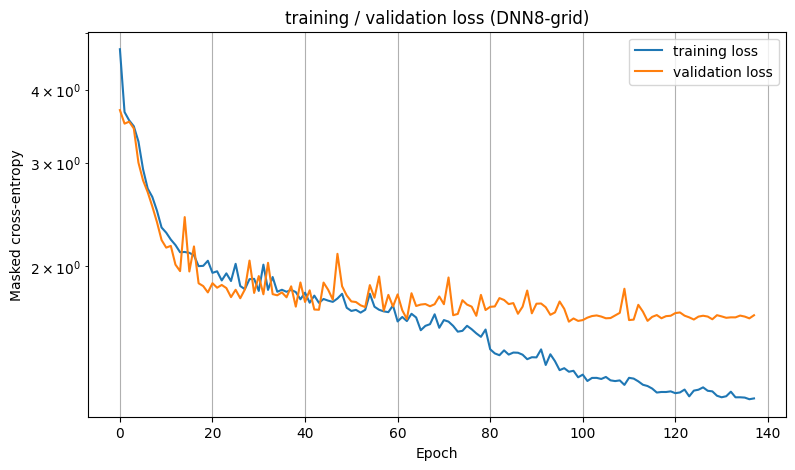

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

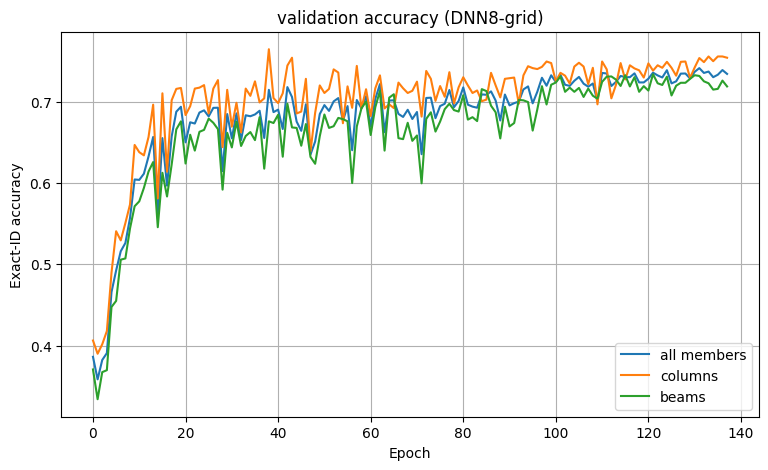

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
# plt.figure(figsize=(9, 5))
# plt.plot(history_df["train_loss"], label="training loss")
# plt.plot(history_df["val_loss"], label="validation loss")
# plt.xlabel("Epoch"); plt.ylabel("Masked cross-entropy"); plt.yscale("log"); plt.grid(True); plt.legend()
# plt.title(f"training / validation loss ({dnn})")
# plt.savefig(OUTPUT_DIR / f"{dnn}-training-validation-loss.png", dpi=150)
# files.download(f"{dnn}-training-validation-loss.png")
# plt.show()
#figure one
hystory_df = pd.read_csv(TRAINING_HISTORY_PATH)
output_path = OUTPUT_DIR / f"{dnn}-training-validation-loss.png"

plt.figure(figsize=(9, 5))
plt.plot(history_df["train_loss"], label="training loss")
plt.plot(history_df["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Masked cross-entropy")
plt.yscale("log")
plt.grid(True)
plt.legend()
plt.title(f"training / validation loss ({dnn})")

# Save before plt.show() so the figure isn't cleared first
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

# Pass the full path where the file was actually saved
files.download(str(output_path))

#figure two
output_path = OUTPUT_DIR / f"{dnn}-validation-accuracy.png"
plt.figure(figsize=(9, 5))
for col, lab in (("val_slot_accuracy", "all members"), ("val_column_accuracy", "columns"), ("val_beam_accuracy", "beams")):
    plt.plot(history_df[col], label=lab)
plt.xlabel("Epoch"); plt.ylabel("Exact-ID accuracy"); plt.grid(True); plt.legend()
plt.title(f"validation accuracy ({dnn})")

# Save before plt.show() so the figure isn't cleared first
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

# Pass the full path where the file was actually saved
files.download(str(output_path))

## Prediction helpers

In [29]:
@torch.no_grad()
def predict_indices(X, batch=64):
    """Return catalog row indices (argmax) for columns (N,F,NY,NX) and beams (N,F,NY,NX,2)."""
    model.eval()
    ics, ibs = [], []
    for s in range(0, len(X), batch):
        lc, lb = model(torch.as_tensor(X[s:s + batch], dtype=torch.float32, device=DEVICE))
        ics.append(lc.argmax(-1).cpu().numpy()); ibs.append(lb.argmax(-1).cpu().numpy())
    return np.concatenate(ics), np.concatenate(ibs)

def to_ids(g, ic, ib):
    """Catalog row indices -> component IDs (-1 where no member exists)."""
    return (np.where(g["col_valid"], cat_col.ids[ic], -1),
            np.where(g["beam_valid"], cat_beam.ids[ib], -1))

def total_weight(g, ic, ib):
    """Steel weight [kg] from catalog mass per metre and member lengths."""
    wc = (cat_col.mass[ic] * g["col_len"] / 1000 * g["col_valid"]).sum()
    wb = (cat_beam.mass[ib] * g["beam_len"] / 1000 * g["beam_valid"]).sum()
    return float(wc + wb)

def results_table(b, g, ic, ib):
    """One row per member: story, grid position, coordinates, catalog ID, name, weight."""
    rows = []
    F, NY, NX = ic.shape
    for f in range(b["n_floors"]):
        for j in range(NY):
            for i in range(NX):
                x0, y0 = b["x_coord"][min(i, b["nx"])], b["y_coord"][min(j, b["ny"])]
                if g["col_valid"][f, j, i]:
                    k = ic[f, j, i]
                    rows.append((f + 1, "column", i + 1, j + 1, x0, y0, g["col_len"][f, j, i],
                                 cat_col.ids[k], cat_col.names[k], cat_col.mass[k] * g["col_len"][f, j, i] / 1000))
                for d, label in enumerate(("beam_X", "beam_Y")):
                    if g["beam_valid"][f, j, i, d]:
                        k = ib[f, j, i, d]
                        rows.append((f + 1, label, i + 1, j + 1, x0, y0, g["beam_len"][f, j, i, d],
                                     cat_beam.ids[k], cat_beam.names[k], cat_beam.mass[k] * g["beam_len"][f, j, i, d] / 1000))
    return pd.DataFrame(rows, columns=["story", "member", "x_line", "y_line", "x_mm", "y_mm",
                                       "length_mm", "catalog_id", "section_name", "weight_kg"])

def show_plan(b, g, ic, ib, story):
    """Print the predicted IDs in a plan-like layout (C = column ID, X/Y = beam IDs)."""
    ids_c, ids_b = to_ids(g, ic, ib)
    f = story - 1
    print(f"--- story {story} (top of story = beam level) ---")
    for j in range(b["ny"], -1, -1):
        line = f"Y{j + 1} "
        for i in range(b["nx"] + 1):
            line += f"[C{ids_c[f, j, i]:>3}]" if ids_c[f, j, i] >= 0 else "[  -  ]"
            if i < b["nx"]:
                line += f"--X{ids_b[f, j, i, 0]:>3}--" if ids_b[f, j, i, 0] >= 0 else "        "
        print(line)
        if j > 0:
            print("   " + "".join(f"{('|Y' + str(ids_b[f, j - 1, i, 1])) if ids_b[f, j - 1, i, 1] >= 0 else '':<14}"
                                  for i in range(b["nx"] + 1)))

## Test evaluation and per-story diagnostics

In [30]:
test = data["test"]
ic_pred, ib_pred = predict_indices(test["X"])
acc_c, acc_b, err_c, err_b, w_err = [], [], [], [], []
story_stats = defaultdict(lambda: dict(c_ok=0, c_n=0, b_ok=0, b_n=0))
exact_buildings = 0
records = []
for n_, b in enumerate(test["buildings"]):
    g = test["G"][n_]
    vc, vb = g["col_valid"], g["beam_valid"]
    tc, tb = np.maximum(test["YC"][n_], 0), np.maximum(test["YB"][n_], 0)
    okc, okb = (ic_pred[n_] == tc), (ib_pred[n_] == tb)
    acc_c.append(okc[vc].mean()); acc_b.append(okb[vb].mean())
    exact_buildings += bool(okc[vc].all() and okb[vb].all())
    err_c.append(np.abs(cat_col.size[ic_pred[n_]] - cat_col.size[tc])[vc].mean())
    err_b.append(np.abs(cat_beam.size[ib_pred[n_]] - cat_beam.size[tb])[vb].mean())
    w_true, w_pred = total_weight(g, tc, tb), total_weight(g, ic_pred[n_], ib_pred[n_])
    w_err.append(abs(w_pred - w_true) / w_true)
    for f in range(b["n_floors"]):
        s = story_stats[f + 1]
        s["c_ok"] += int(okc[f][vc[f]].sum()); s["c_n"] += int(vc[f].sum())
        s["b_ok"] += int(okb[f][vb[f]].sum()); s["b_n"] += int(vb[f].sum())
        for j in range(spec["NY"]):
            for i in range(spec["NX"]):
                if vc[f, j, i]:
                    records.append(dict(file_name=os.path.basename(b["path"]), story=f + 1, member="column",
                                        x_line=i + 1, y_line=j + 1,
                                        true_id=int(cat_col.ids[tc[f, j, i]]), true_name=cat_col.names[tc[f, j, i]],
                                        predicted_id=int(cat_col.ids[ic_pred[n_][f, j, i]]),
                                        predicted_name=cat_col.names[ic_pred[n_][f, j, i]],
                                        is_correct=bool(okc[f, j, i])))
                for d, lab in enumerate(("beam_X", "beam_Y")):
                    if vb[f, j, i, d]:
                        records.append(dict(file_name=os.path.basename(b["path"]), story=f + 1, member=lab,
                                            x_line=i + 1, y_line=j + 1,
                                            true_id=int(cat_beam.ids[tb[f, j, i, d]]), true_name=cat_beam.names[tb[f, j, i, d]],
                                            predicted_id=int(cat_beam.ids[ib_pred[n_][f, j, i, d]]),
                                            predicted_name=cat_beam.names[ib_pred[n_][f, j, i, d]],
                                            is_correct=bool(okb[f, j, i, d])))

lines = [f"{dnn} TEST RESULTS", "=" * 60,
         f"Test buildings        : {len(test['buildings'])}",
         f"Exact ID accuracy     : columns {np.mean(acc_c):.5f} | beams {np.mean(acc_b):.5f}",
         f"Building exact match  : {exact_buildings / len(test['buildings']):.5f}",
         f"Mean abs. size error  : column D {np.mean(err_c):.1f} mm | beam H {np.mean(err_b):.1f} mm",
         f"Total weight error    : {np.mean(w_err):.2%} (mean relative)",
         "", "Accuracy by story:"]
for st, s in sorted(story_stats.items()):
    lines.append(f"{st:>4}FL | beam={s['b_ok'] / max(s['b_n'], 1):.5f} ({s['b_n']}) | column={s['c_ok'] / max(s['c_n'], 1):.5f} ({s['c_n']})")
print("\n".join(lines))

predictions = pd.DataFrame(records)
predictions.to_csv(PREDICTIONS_PATH, index=False, encoding="utf-8-sig")
RESULTS_TEXT_PATH.write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\nSaved predictions :", PREDICTIONS_PATH)
print("Saved results text:", RESULTS_TEXT_PATH)
display(predictions.head(20))

DNN8-grid TEST RESULTS
Test buildings        : 90
Exact ID accuracy     : columns 0.78257 | beams 0.70512
Building exact match  : 0.00000
Mean abs. size error  : column D 5.0 mm | beam H 27.0 mm
Total weight error    : 3.04% (mean relative)

Accuracy by story:
   1FL | beam=0.67066 (1002) | column=0.70812 (788)
   2FL | beam=0.82934 (1002) | column=0.79695 (788)
   3FL | beam=0.58383 (1002) | column=0.85533 (788)

Saved predictions : /content/drive/MyDrive/research/dnn8/dnn-results/dnn8-test-predictions.csv
Saved results text: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-results.txt


,file_name,story,member,x_line,y_line,true_id,true_name,predicted_id,predicted_name,is_correct
0,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,1,1,8,B-200x200x8x20,4,B-175x175x6x15,False
1,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_X,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
2,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_Y,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
3,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,2,1,8,B-200x200x8x20,4,B-175x175x6x15,False
4,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_Y,2,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
5,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,1,2,8,B-200x200x8x20,4,B-175x175x6x15,False
6,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_X,1,2,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
7,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,2,2,8,B-200x200x8x20,4,B-175x175x6x15,False
8,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,2,column,1,1,5,B-175x175x9x22.5,8,B-200x200x8x20,False
9,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,2,beam_X,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True


## Prediction for a new building (from a model CSV)

In [31]:
# Predict a new building from a CSV (building parameters are read from the file contents)
def predict_from_csv(path, save=True):
    b = parse_building(path, need_labels=False)           # section lists are not required here
    X, g = encode_building(b, spec)
    ic, ib = predict_indices(X[None])
    ic, ib = ic[0], ib[0]
    df = results_table(b, g, ic, ib)
    print(f"{os.path.basename(path)}: {b['n_floors']} story, {b['nx']} X-span(s) {b['x_spans']}, "
          f"{b['ny']} Y-span(s) {b['y_spans']}, heights {b['heights']}, load {b['load']} kN/m2")
    for s in range(1, b["n_floors"] + 1):
        show_plan(b, g, ic, ib, s)
    print(f"Estimated steel weight: {total_weight(g, ic, ib):.1f} kg")
    if save:
        out = os.path.join(OUTPUT_DIR, "pred_" + os.path.basename(path))
        df.to_csv(out, index=False, encoding="utf-8-sig")
        print("Saved:", out)
    return df

# Example: predict the first three test buildings (replace with the path of any new building CSV)
for p in sorted(glob.glob(str(DATASET_ROOT / "test" / "*.csv")))[:3]:
    display(predict_from_csv(p).head(30))

F3_X1_4000_Y1_4000_H3500_W6p0_model.csv: 3 story, 1 X-span(s) [4000.0], 1 Y-span(s) [4000.0], heights {3: 3500.0, 2: 3500.0, 1: 3500.0}, load 6.0 kN/m2
--- story 1 (top of story = beam level) ---
Y2 [C  4]--X  7--[C  4]
   |Y7           |Y7           
Y1 [C  4]--X  7--[C  4]
--- story 2 (top of story = beam level) ---
Y2 [C  8]--X  7--[C  8]
   |Y7           |Y7           
Y1 [C  8]--X  7--[C  8]
--- story 3 (top of story = beam level) ---
Y2 [C  3]--X  4--[C  3]
   |Y4           |Y4           
Y1 [C  3]--X  4--[C  3]
Estimated steel weight: 2973.2 kg
Saved: /content/drive/MyDrive/research/dnn8/dnn-results/pred_F3_X1_4000_Y1_4000_H3500_W6p0_model.csv


,story,member,x_line,y_line,x_mm,y_mm,length_mm,catalog_id,section_name,weight_kg
0,1,column,1,1,0.0,0.0,3500.0,4,B-175x175x6x15,108.0415
1,1,beam_X,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840
2,1,beam_Y,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840
3,1,column,2,1,4000.0,0.0,3500.0,4,B-175x175x6x15,108.0415
4,1,beam_Y,2,1,4000.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840
5,1,column,1,2,0.0,4000.0,3500.0,4,B-175x175x6x15,108.0415
6,1,beam_X,1,2,0.0,4000.0,4000.0,7,H-250x125x6x9x8,116.0840
7,1,column,2,2,4000.0,4000.0,3500.0,4,B-175x175x6x15,108.0415
8,2,column,1,1,0.0,0.0,3500.0,8,B-200x200x8x20,162.7675
9,2,beam_X,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840


F3_X1_5000_Y1_4000_H3000_W10p0_model.csv: 3 story, 1 X-span(s) [5000.0], 1 Y-span(s) [4000.0], heights {3: 3000.0, 2: 3000.0, 1: 3000.0}, load 10.0 kN/m2
--- story 1 (top of story = beam level) ---
Y2 [C 13]--X  8--[C 13]
   |Y8           |Y8           
Y1 [C 13]--X  8--[C 13]
--- story 2 (top of story = beam level) ---
Y2 [C 13]--X  8--[C 13]
   |Y8           |Y8           
Y1 [C 13]--X  8--[C 13]
--- story 3 (top of story = beam level) ---
Y2 [C 11]--X 15--[C 11]
   |Y15          |Y15          
Y1 [C 11]--X 15--[C 11]
Estimated steel weight: 4304.6 kg
Saved: /content/drive/MyDrive/research/dnn8/dnn-results/pred_F3_X1_5000_Y1_4000_H3000_W10p0_model.csv


,story,member,x_line,y_line,x_mm,y_mm,length_mm,catalog_id,section_name,weight_kg
0,1,column,1,1,0.0,0.0,3000.0,13,B-250x250x8x20,177.195
1,1,beam_X,1,1,0.0,0.0,5000.0,8,H-300x150x6.5x9x13,183.615
2,1,beam_Y,1,1,0.0,0.0,4000.0,8,H-300x150x6.5x9x13,146.892
3,1,column,2,1,5000.0,0.0,3000.0,13,B-250x250x8x20,177.195
4,1,beam_Y,2,1,5000.0,0.0,4000.0,8,H-300x150x6.5x9x13,146.892
5,1,column,1,2,0.0,4000.0,3000.0,13,B-250x250x8x20,177.195
6,1,beam_X,1,2,0.0,4000.0,5000.0,8,H-300x150x6.5x9x13,183.615
7,1,column,2,2,5000.0,4000.0,3000.0,13,B-250x250x8x20,177.195
8,2,column,1,1,0.0,0.0,3000.0,13,B-250x250x8x20,177.195
9,2,beam_X,1,1,0.0,0.0,5000.0,8,H-300x150x6.5x9x13,183.615


F3_X1_5000_Y1_4000_H3000_W7p0_model.csv: 3 story, 1 X-span(s) [5000.0], 1 Y-span(s) [4000.0], heights {3: 3000.0, 2: 3000.0, 1: 3000.0}, load 7.0 kN/m2
--- story 1 (top of story = beam level) ---
Y2 [C  8]--X  7--[C  8]
   |Y7           |Y7           
Y1 [C  8]--X  7--[C  8]
--- story 2 (top of story = beam level) ---
Y2 [C  8]--X  8--[C  8]
   |Y8           |Y8           
Y1 [C  8]--X  8--[C  8]
--- story 3 (top of story = beam level) ---
Y2 [C  3]--X  4--[C  3]
   |Y4           |Y4           
Y1 [C  3]--X  4--[C  3]
Estimated steel weight: 3200.5 kg
Saved: /content/drive/MyDrive/research/dnn8/dnn-results/pred_F3_X1_5000_Y1_4000_H3000_W7p0_model.csv


,story,member,x_line,y_line,x_mm,y_mm,length_mm,catalog_id,section_name,weight_kg
0,1,column,1,1,0.0,0.0,3000.0,8,B-200x200x8x20,139.515
1,1,beam_X,1,1,0.0,0.0,5000.0,7,H-250x125x6x9x8,145.105
2,1,beam_Y,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.084
3,1,column,2,1,5000.0,0.0,3000.0,8,B-200x200x8x20,139.515
4,1,beam_Y,2,1,5000.0,0.0,4000.0,7,H-250x125x6x9x8,116.084
5,1,column,1,2,0.0,4000.0,3000.0,8,B-200x200x8x20,139.515
6,1,beam_X,1,2,0.0,4000.0,5000.0,7,H-250x125x6x9x8,145.105
7,1,column,2,2,5000.0,4000.0,3000.0,8,B-200x200x8x20,139.515
8,2,column,1,1,0.0,0.0,3000.0,8,B-200x200x8x20,139.515
9,2,beam_X,1,1,0.0,0.0,5000.0,8,H-300x150x6.5x9x13,183.615


## Visualize predictions

In [32]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [33]:
from pathlib import Path
print(Path.cwd())

/content/drive/My Drive/research/dnn8


In [34]:
import os

# Check the current working directory
print("Before:", os.getcwd())

# Change to a new directory (absolute or relative path)
os.chdir("/content/drive/MyDrive/research/dnn8")

# Verify the change
print("After (Current Working Directory):", os.getcwd())


Before: /content/drive/My Drive/research/dnn8
After (Current Working Directory): /content/drive/MyDrive/research/dnn8


In [35]:
# 2. Load the CSV file using its path in your Drive
# (Adjust the path below to match where your file is located)
file_path = "/content/drive/MyDrive/research/dnn8/dnn-results/dnn8-test-predictions.csv"
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,file_name,story,member,x_line,y_line,true_id,true_name,predicted_id,predicted_name,is_correct
0,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,1,1,8,B-200x200x8x20,4,B-175x175x6x15,False
1,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_X,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
2,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_Y,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
3,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,2,1,8,B-200x200x8x20,4,B-175x175x6x15,False
4,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_Y,2,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True


In [37]:
print(df)

                                     file_name  story  member  x_line  y_line  \
0      F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  column       1       1   
1      F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  beam_X       1       1   
2      F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  beam_Y       1       1   
3      F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  column       2       1   
4      F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  beam_Y       2       1   
...                                        ...    ...     ...     ...     ...   
5365  F3_X6_9000_Y1_4000_H4500_W10p0_model.csv      3  column       5       2   
5366  F3_X6_9000_Y1_4000_H4500_W10p0_model.csv      3  beam_X       5       2   
5367  F3_X6_9000_Y1_4000_H4500_W10p0_model.csv      3  column       6       2   
5368  F3_X6_9000_Y1_4000_H4500_W10p0_model.csv      3  beam_X       6       2   
5369  F3_X6_9000_Y1_4000_H4500_W10p0_model.csv      3  column       7       2   

      true_id          true

In [38]:
import pandas as pd
import numpy as np
import re

# ============================================================
# Nominal dimensions are taken from the CATALOG files.
#   H-shape : nominal_H_mm, nominal_B_mm   (e.g. H-244x175x7x11x13 -> 250, 175)
#   BCR box : D_mm, t_mm                   (e.g. B-200x200x8x20    -> 200, 8)
# A name in `df` may be either
#   * an exact section name  (H-244x175x7x11x13 / B-200x200x8x20), or
#   * a nominal class name   (H-250x175 / B-200x8)
# Both are resolved to the same nominal values, so older and newer
# prediction files work with the same code.
# ============================================================

def _read_catalog_csv(path):
    return pd.read_csv(path, encoding='utf-8-sig')

h_cat = _read_catalog_csv(CATALOG_ROOT / H_CATALOG_FILE)    # all rows, incl. enabled == 0
box_cat = _read_catalog_csv(CATALOG_ROOT / BOX_CATALOG_FILE)

def build_lookup(cat, key_cols, prefix):
    lookup = {}
    for _, r in cat.iterrows():
        vals = tuple(float(r[c]) for c in key_cols)
        lookup[str(r['name']).strip()] = vals                              # exact name
        lookup[f'{prefix}-' + 'x'.join(f'{v:g}' for v in vals)] = vals     # nominal class name
    return lookup

H_LOOKUP = build_lookup(h_cat, ('nominal_H_mm', 'nominal_B_mm'), 'H')
BOX_LOOKUP = build_lookup(box_cat, ('D_mm', 't_mm'), 'B')

def normalize_name(name):
    if pd.isna(name):
        return None
    name = str(name).strip()
    return re.sub(r'^[□■]\s*-?\s*', 'B-', name)       # □-200x200x8x20 -> B-200x200x8x20

def get_section_type(name):
    name = normalize_name(name)
    if name is None:
        return np.nan
    if name.startswith('H-'):
        return 'h'
    if name.startswith('B-'):
        return 'box'
    return np.nan

def nominal_dims(name, section_type):
    """name -> (nominal H, nominal B) for 'h',  (D, t) for 'box',  (nan, nan) otherwise."""
    name = normalize_name(name)
    if name is not None:
        lookup = H_LOOKUP if section_type == 'h' else BOX_LOOKUP if section_type == 'box' else {}
        if name in lookup:
            return lookup[name]
    return (np.nan, np.nan)

df_transformed = df.copy()
df_transformed['section_type'] = df_transformed['true_catalog'].apply(get_section_type)

def add_dims(prefix, name_col):
    """Add {prefix}_H/_B (beams) and {prefix}_D/_t (columns) from the catalog."""
    dims = [nominal_dims(n, get_section_type(n)) for n in df_transformed[name_col]]
    is_h = df_transformed[name_col].apply(get_section_type).eq('h').to_numpy()
    arr = np.array(dims, dtype=float)
    df_transformed[f'{prefix}_H'] = np.where(is_h, arr[:, 0], np.nan)
    df_transformed[f'{prefix}_B'] = np.where(is_h, arr[:, 1], np.nan)
    df_transformed[f'{prefix}_D'] = np.where(~is_h, arr[:, 0], np.nan)
    df_transformed[f'{prefix}_t'] = np.where(~is_h, arr[:, 1], np.nan)

add_dims('pred', 'predicted_catalog')
add_dims('true', 'true_catalog')

# names that could not be found in the catalog
for col in ('predicted_catalog', 'true_catalog'):
    p = 'pred' if col == 'predicted_catalog' else 'true'
    unresolved = df_transformed[
        df_transformed[col].notna()
        & df_transformed[[f'{p}_H', f'{p}_D']].isna().all(axis=1)
    ][col].unique()
    if len(unresolved):
        print(f'WARNING: {col} names not found in catalog:', list(unresolved)[:10])

# is_correct judged on the nominal class (exact names that share a nominal size count as equal)
df_transformed['is_correct_nominal'] = (
    df_transformed[['pred_H', 'pred_B', 'pred_D', 'pred_t']].fillna(-1)
    .eq(df_transformed[['true_H', 'true_B', 'true_D', 'true_t']].fillna(-1).to_numpy()).all(axis=1)
)

df_transformed = df_transformed[
    [
        'file_name', 'slot', 'section_type',
        'predicted_catalog', 'true_catalog', 'is_correct', 'is_correct_nominal',
        'pred_H', 'pred_B', 'pred_D', 'pred_t',
        'true_H', 'true_B', 'true_D', 'true_t',
    ]
]

print(df_transformed.head())
print(df_transformed.shape)

KeyError: 'true_catalog'